In [1]:
import dill
import scanpy as sc
import anndata as ad
#import muon as mu
import os
import warnings
warnings.filterwarnings("ignore")
import pandas
import pyranges
# Set stderr to null to avoid strange messages from ray
import sys
_stderr = sys.stderr
null = open(os.devnull,'wb')

from pycisTopic.cistopic_class import CistopicObject
from pycisTopic.lda_models import *
from pycisTopic.clust_vis import *
from pycisTopic.diff_features import *

from scenicplus.scenicplus_class import SCENICPLUS, create_SCENICPLUS_object
from scenicplus.preprocessing.filtering import *
from scenicplus.utils import region_names_to_coordinates
from scenicplus.eregulon_enrichment import make_rankings

from scenicplus.wrappers.run_scenicplus import run_scenicplus

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from scenicplus_modified_dotplot import *

In [2]:
%config InlineBackend.figure_format = 'retina'

In [3]:
## Set up work directory
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'
## Tmp dir for ray (this needs to be as short as possible, as there is an overall limit of the number of characters accepted by ray - max is 107):
tmp_dir = '/lustre/scratch125/casm/teams/team215/r/'
os.makedirs(tmp_dir, exist_ok=True)

grouping_variable = 'GEX_perturbation'

In [4]:
output_dir = work_dir + 'scenicplus_full/eRegulon_dimred/'
os.makedirs(output_dir, exist_ok=True)

In [5]:
## Restart kernel and reload preinitialised scplus object:
scplus_obj = dill.load(open((work_dir + 'scenicplus_full/scplus_obj_with_regulons.pkl'), 'rb'))

In [6]:
scplus_obj

SCENIC+ object with n_cells x n_genes = 246 x 16752 and n_cells x n_regions = 246 x 36627
	metadata_genes:'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
	metadata_cell:'GEX_perturbation', 'GEX_perturbation_purity', 'GEX_n_genes_by_counts', 'GEX_log1p_n_genes_by_counts', 'GEX_total_counts', 'GEX_log1p_total_counts', 'GEX_pct_counts_in_top_50_genes', 'GEX_pct_counts_in_top_100_genes', 'GEX_pct_counts_in_top_200_genes', 'GEX_pct_counts_in_top_500_genes', 'ACC_rna:perturbation', 'ACC_rna:perturbation_purity', 'ACC_rna:n_genes_by_counts', 'ACC_rna:log1p_n_genes_by_counts', 'ACC_rna:total_counts', 'ACC_rna:log1p_total_counts', 'ACC_rna:pct_counts_in_top_50_genes', 'ACC_rna:pct_counts_in_top_100_genes', 'ACC_rna:pct_counts_in_top_200_genes', 'ACC_rna:pct_counts_in_top_500_genes', 'ACC_atac:perturbation', 'ACC_atac:perturbation_purity', 'ACC_perturbation', 'ACC_perturbation_purity', 'ACC_compactness', 'ACC_size'
	menr:'CTX

In [7]:
# # Simplifying and filtering SCENIC+ output
# from scenicplus.preprocessing.filtering import apply_std_filtering_to_eRegulons
# apply_std_filtering_to_eRegulons(scplus_obj)

## eRegulon dimensionality reduction

In [8]:
# To calculate these dimensionality reductions we use both the regions and gene based enrichment scores
from scenicplus.dimensionality_reduction import run_eRegulons_tsne, run_eRegulons_umap
run_eRegulons_umap(
    scplus_obj = scplus_obj,
    auc_key = 'eRegulon_AUC_filtered',
    reduction_name = 'eRegulons_UMAP', #overwrite previously calculated UMAP
)
run_eRegulons_tsne(
    scplus_obj = scplus_obj,
    auc_key = 'eRegulon_AUC_filtered',
    reduction_name = 'eRegulons_tSNE', #overwrite previously calculated tSNE
)

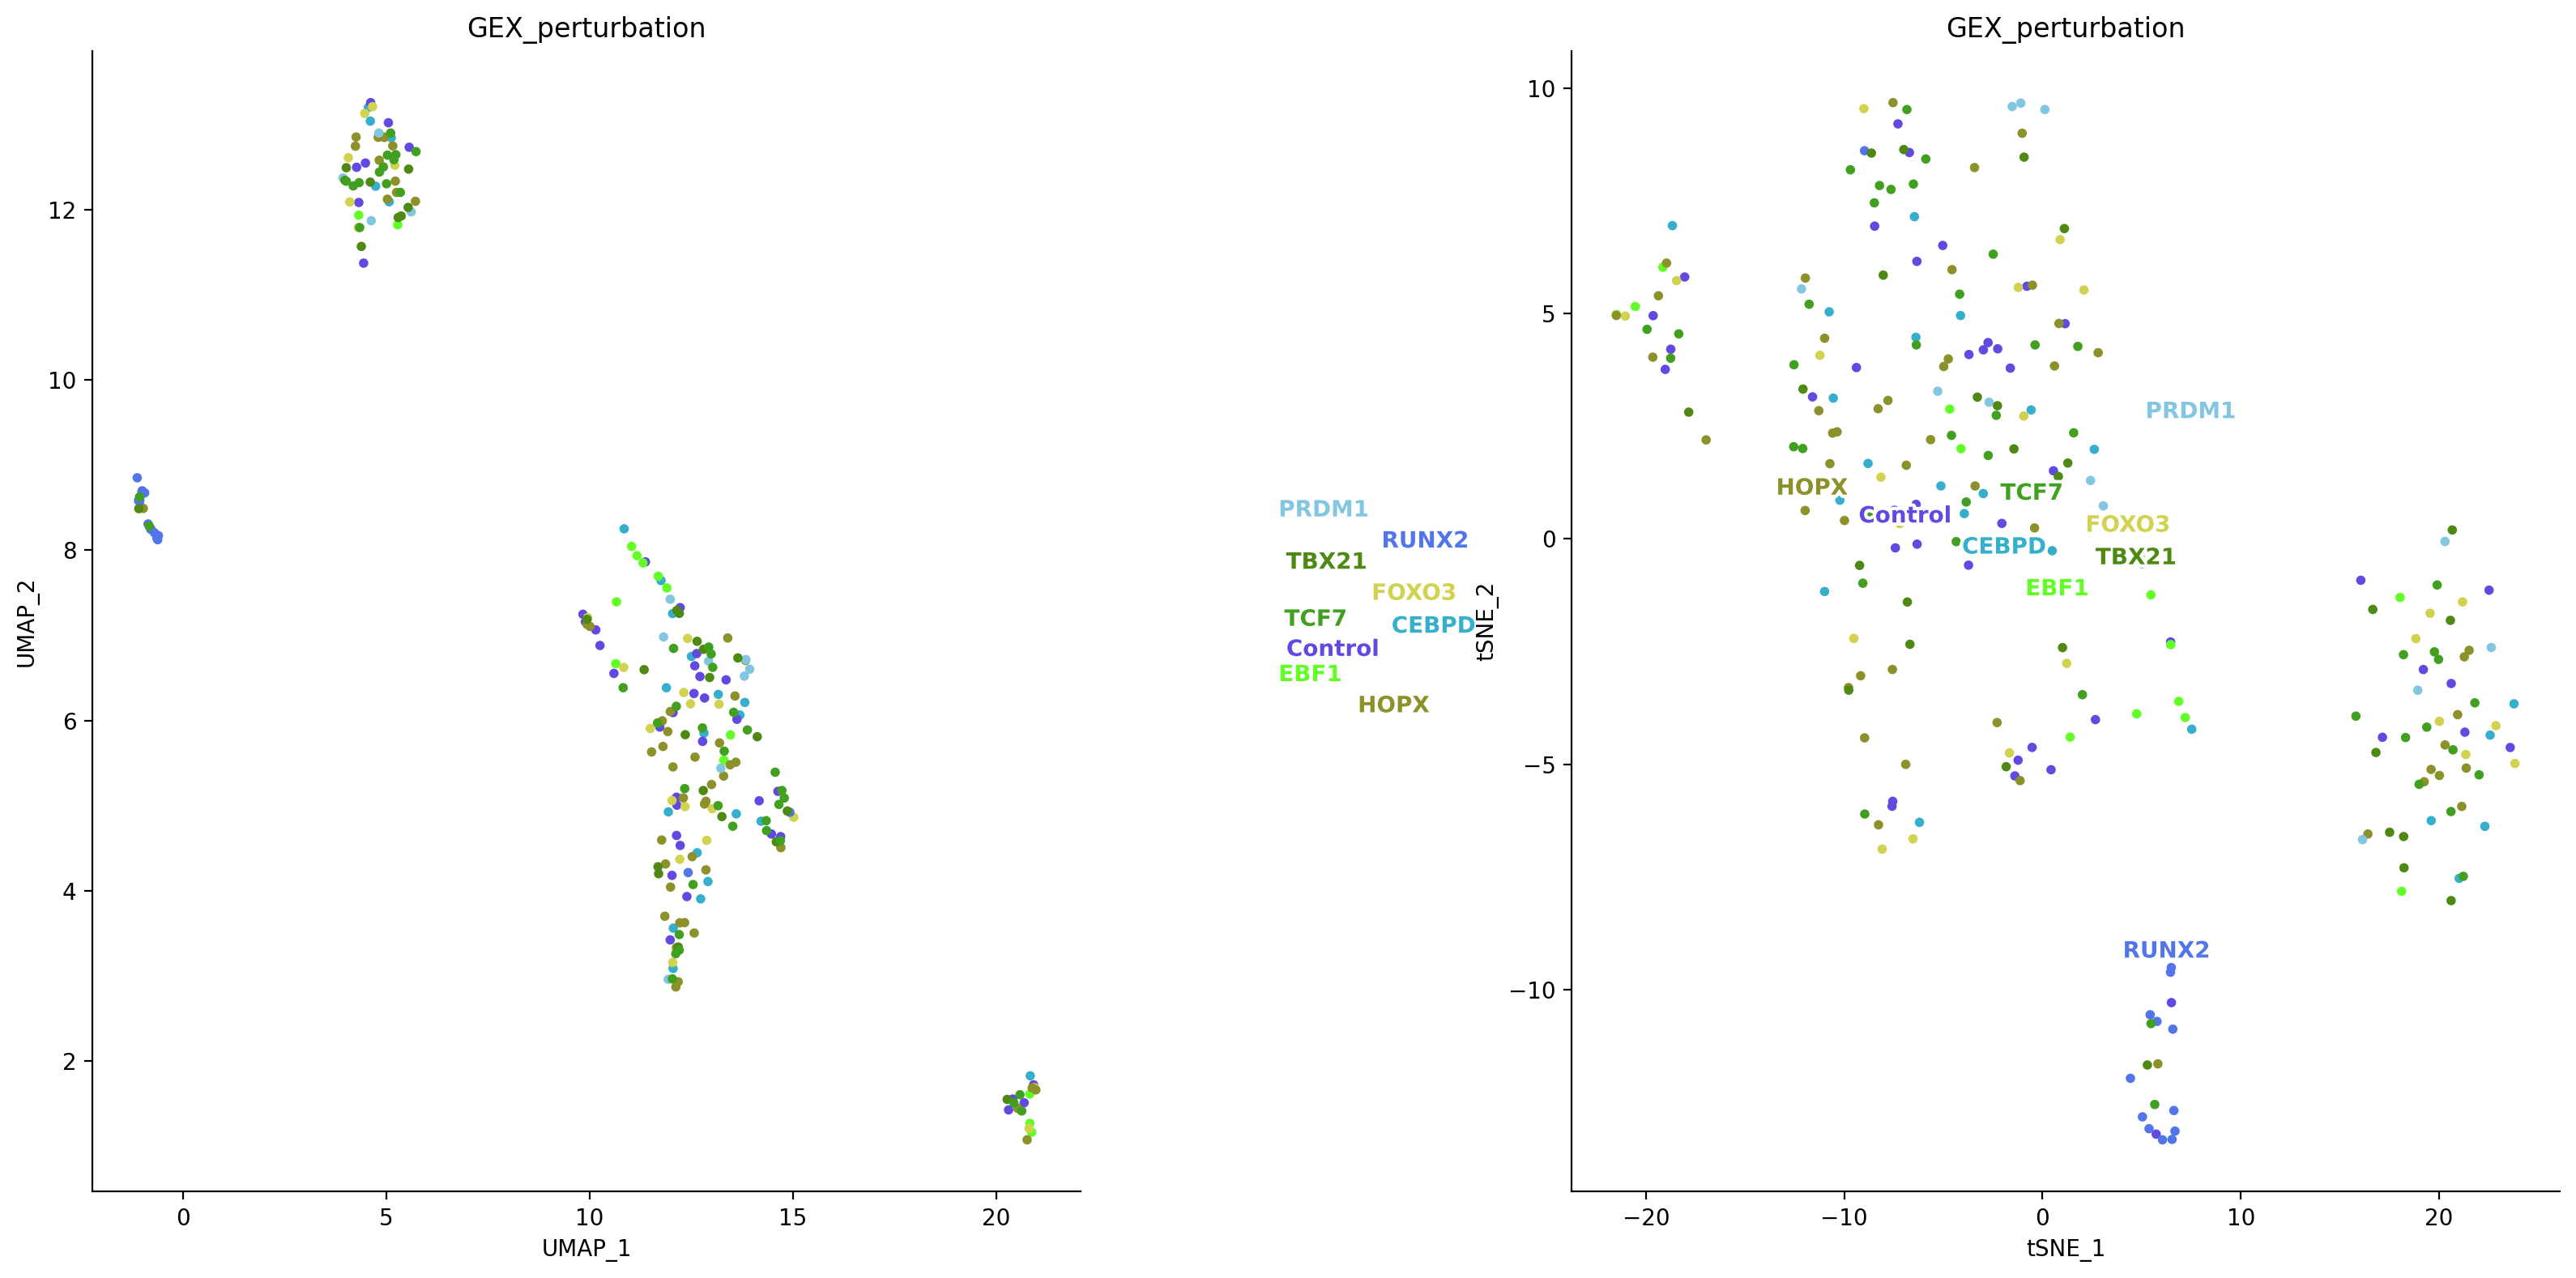

In [9]:
from scenicplus.dimensionality_reduction import plot_metadata_given_ax
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

fig, axs = plt.subplots(ncols=2, figsize = (16, 8))
plot_metadata_given_ax(
    scplus_obj=scplus_obj,
    ax = axs[0],
    reduction_name = 'eRegulons_UMAP',
    variable = 'GEX_perturbation'#, #note the GEX_ prefix, this metadata originated from the gene expression metadata (on which we did the cell type annotation before)
    # color_dictionary={'GEX_celltype': color_dict}
)
plot_metadata_given_ax(
    scplus_obj=scplus_obj,
    ax = axs[1],
    reduction_name = 'eRegulons_tSNE',
    variable = 'GEX_perturbation'#, #note the GEX_ prefix, this metadata originated from the gene expression metadata (on which we did the cell type annotation before)
    # color_dictionary={'GEX_celltype': color_dict}
)
fig.tight_layout()
sns.despine(ax = axs[0]) #remove top and right edge of axis border
sns.despine(ax = axs[1]) #remove top and right edge of axis border
plt.show()

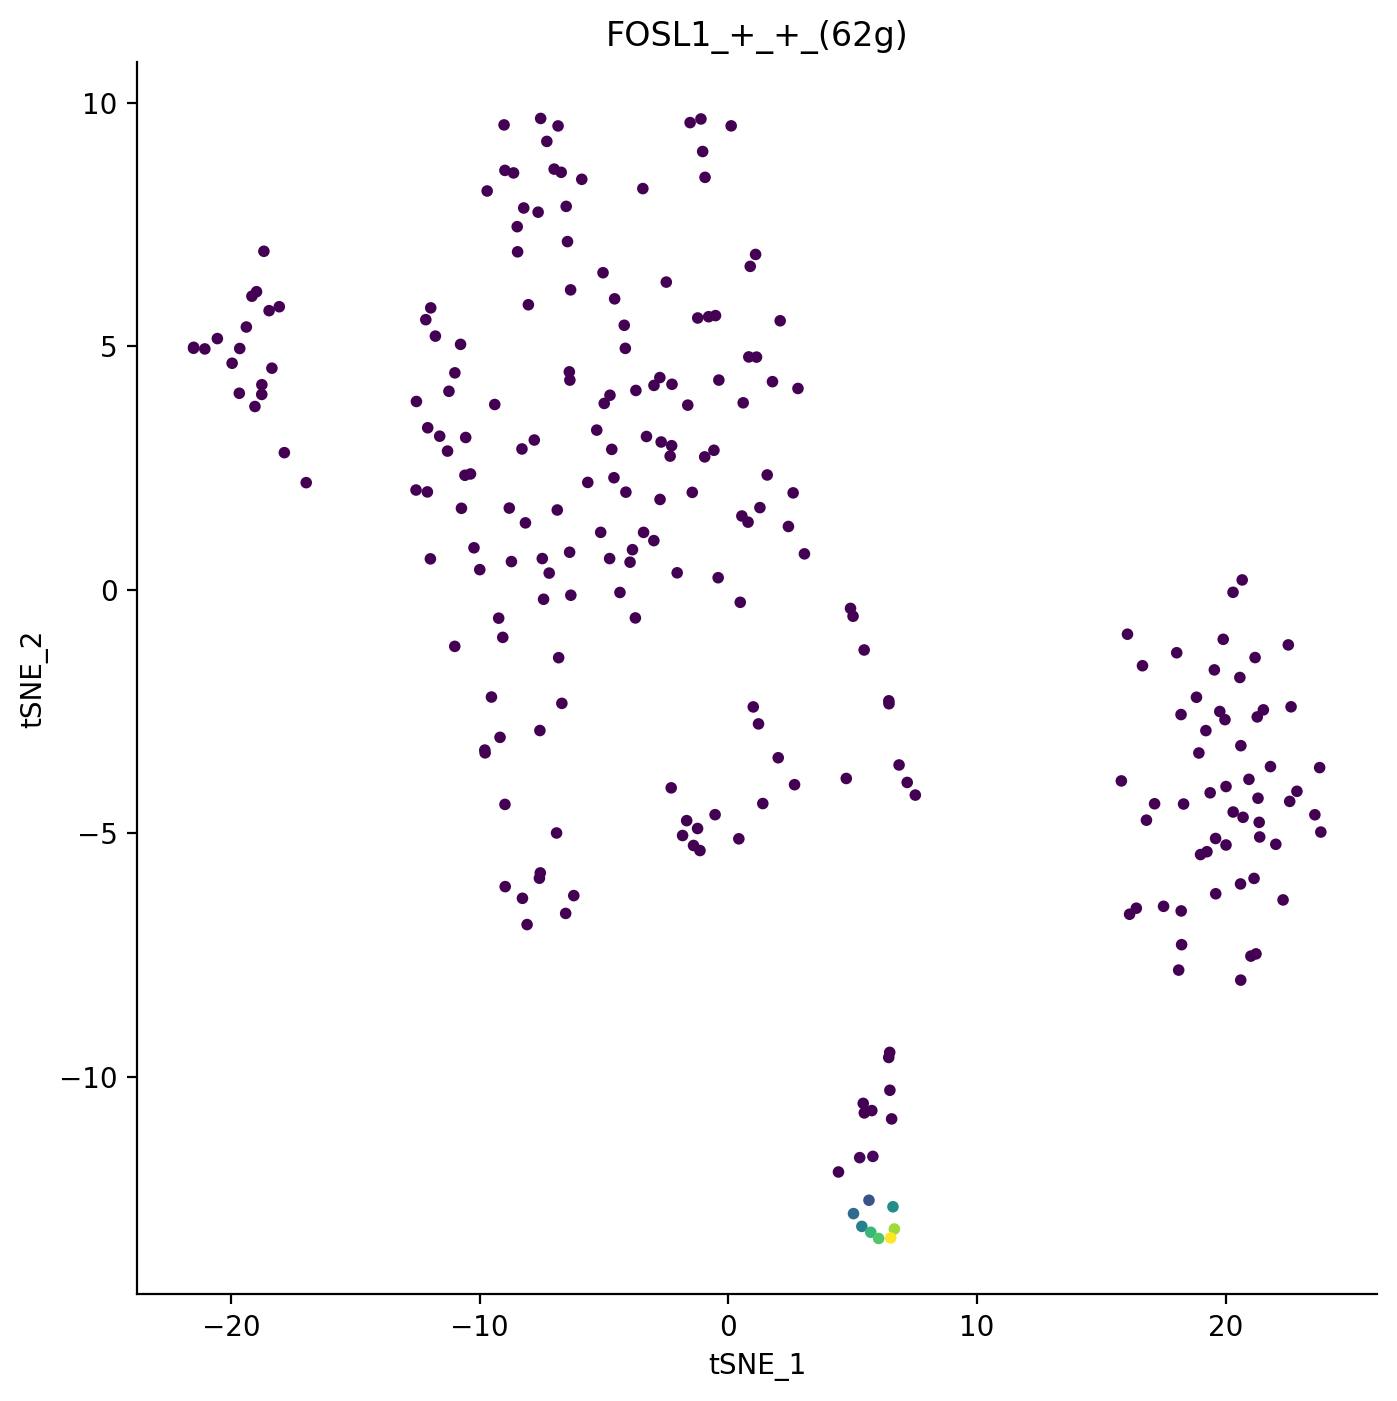

In [10]:
# Plot only the activity of an eRegulon
from scenicplus.dimensionality_reduction import plot_AUC_given_ax

fig, ax = plt.subplots(figsize = (8,8))
plot_AUC_given_ax(
    scplus_obj = scplus_obj,
    reduction_name = 'eRegulons_tSNE',
    feature = 'FOSL1_+_+_(62g)',
    ax = ax,
    auc_key = 'eRegulon_AUC_filtered',
    signature_key = 'Gene_based')
sns.despine(ax = ax)
plt.show()

In [11]:
scplus_obj.uns['selected_eRegulon']['Gene_based']

['TEAD1_+_+_(98g)',
 'CEBPZ_-_+_(71g)',
 'NFE2L2_+_+_(92g)',
 'KLF6_-_+_(36g)',
 'JUND_+_+_(59g)',
 'SMAD3_+_+_(50g)',
 'ZSCAN10_-_+_(347g)',
 'CEBPZ_+_+_(347g)',
 'RUNX2_+_+_(44g)',
 'MEF2A_-_+_(86g)',
 'POU2F1_+_+_(64g)',
 'POU5F1_+_+_(616g)',
 'ZEB1_+_+_(178g)',
 'MEF2A_+_+_(60g)',
 'FOSL1_+_+_(62g)',
 'MBNL2_+_+_(60g)',
 'MEIS2_-_+_(268g)',
 'SP5_+_+_(68g)',
 'ZSCAN10_+_+_(242g)',
 'MEIS2_+_+_(237g)',
 'BPTF_-_+_(49g)',
 'KLF7_-_+_(166g)',
 'BACH2_+_+_(164g)',
 'KLF6_+_+_(294g)',
 'HMGA1_-_+_(155g)']

## Overlap of predicted target regions

In [12]:
## Let’s look at the overlap of target regions of the top 5 TFs per cell type based on the Regulon Specificity Score (RSS)

# Select the top 10 eRegulons per cell type
flat_list = lambda t: [item for sublist in t for item in sublist]
selected_markers = list(set(flat_list(
    [scplus_obj.uns['RSS']['GEX_perturbation_filtered'].loc[celltype].sort_values(ascending = False).head(10).index.to_list()
    for celltype in scplus_obj.uns['RSS']['GEX_perturbation_filtered'].index])))

In [13]:
selected_markers

['SMAD3_+_+_(64r)',
 'NFE2L2_+_+_(108r)',
 'ZEB1_+_+_(190r)',
 'JUND_+_+_(63r)',
 'ZSCAN10_+_+_(345r)',
 'MEF2A_+_+_(67r)',
 'BACH2_+_+_(172r)',
 'POU2F1_+_+_(78r)',
 'MBNL2_+_+_(70r)',
 'MEIS2_+_+_(398r)',
 'SP5_+_+_(71r)',
 'CEBPZ_+_+_(412r)',
 'KLF6_+_+_(556r)',
 'POU5F1_+_+_(732r)',
 'RUNX2_+_+_(54r)',
 'TEAD1_+_+_(105r)',
 'FOSL1_+_+_(71r)']

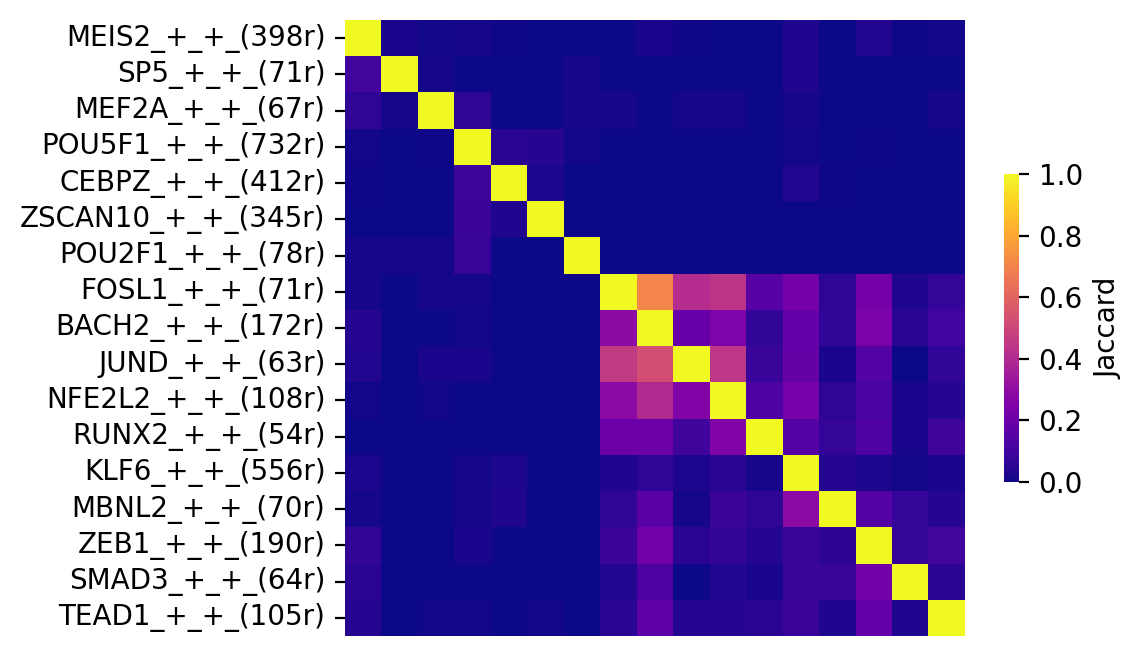

In [15]:
from scenicplus.plotting.correlation_plot import *

region_intersetc_data, Z = jaccard_heatmap(
        scplus_obj,
        method = 'intersect',
        gene_or_region_based = 'Region_based',
        use_plotly = False,
        selected_regulons = selected_markers,
        signature_key = 'eRegulon_signatures',
        figsize = (5,4), return_data = True, vmax = 1, cmap = 'plasma')

## Plotting a network

In [16]:
# We will use the top 1000 highly variable regions and genes
from pycisTopic.diff_features import find_highly_variable_features
hvr = find_highly_variable_features(scplus_obj.to_df('ACC').loc[list(set(scplus_obj.uns['eRegulon_metadata']['Region']))], n_top_features=1000, plot = False)
hvg = find_highly_variable_features(scplus_obj.to_df('EXP')[list(set(scplus_obj.uns['eRegulon_metadata']['Gene']))].T, n_top_features=1000, plot = False)

2026-07-23 21:53:41,313 cisTopic     INFO     Calculating mean
2026-07-23 21:53:41,317 cisTopic     INFO     Calculating variance
2026-07-23 21:53:41,456 cisTopic     INFO     Done!
2026-07-23 21:53:41,468 cisTopic     INFO     Calculating mean
2026-07-23 21:53:41,471 cisTopic     INFO     Calculating variance
2026-07-23 21:53:41,522 cisTopic     INFO     Done!


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [17]:
# Format the eRegulons into a table which can be used to create a network
from scenicplus.networks import create_nx_tables, create_nx_graph, plot_networkx, export_to_cytoscape
nx_tables = create_nx_tables(
    scplus_obj = scplus_obj,
    eRegulon_metadata_key ='eRegulon_metadata',
    subset_eRegulons = ['RUNX2', 'BACH2', 'FOSL1', 'ZEB1', 'NFE2L2', 'POU5F1'],
    subset_regions = hvr,
    subset_genes = hvg,
    add_differential_gene_expression = True,
    add_differential_region_accessibility = True,
    differential_variable = ['GEX_perturbation'])

In [18]:
# Layout the graph
G, pos, edge_tables, node_tables = create_nx_graph(nx_tables,
                   use_edge_tables = ['TF2R','R2G'],
                   color_edge_by = {'TF2R': {'variable' : 'TF', 'category_color' : {'RUNX2': 'Orange', 'BACH2': 'Purple', 'FOSL1': 'Red', 'ZEB1': 'Brown', 'NFE2L2': 'Blue', 'POU5F1': 'Olive'}}},
                                    #'R2G': {'variable' : 'R2G_rho', 'continuous_color' : 'viridis', 'v_min': -1, 'v_max': 1}},
                   #
                   # color_node_by = {'TF': {'variable': 'TF', 'category_color' : {'PAX5': 'Orange', 'EBF1': 'Purple', 'POU2AF1': 'Red'}},
                   #                  'Gene': {'variable': 'GEX_celltype_Log2FC_B_cells_1', 'continuous_color' : 'bwr'},
                   #                  'Region': {'variable': 'GEX_celltype_Log2FC_B_cells_1', 'continuous_color' : 'viridis'}},
                   # transparency_node_by =  {'Region': {'variable' : 'GEX_celltype_Log2FC_B_cells_1', 'min_alpha': 0.1},
                   #                  'Gene': {'variable' : 'GEX_celltype_Log2FC_B_cells_1', 'min_alpha': 0.1}},
                   size_node_by = {'TF': {'variable': 'fixed_size', 'fixed_size': 30},
                                    'Gene': {'variable': 'fixed_size', 'fixed_size': 15},
                                    'Region': {'variable': 'fixed_size', 'fixed_size': 10}},
                   shape_node_by = {'TF': {'variable': 'fixed_shape', 'fixed_shape': 'ellipse'},
                                    'Gene': {'variable': 'fixed_shape', 'fixed_shape': 'ellipse'},
                                    'Region': {'variable': 'fixed_shape', 'fixed_shape': 'diamond'}},
                   label_size_by = {'TF': {'variable': 'fixed_label_size', 'fixed_label_size': 20.0},
                                    'Gene': {'variable': 'fixed_label_size', 'fixed_label_size': 10.0},
                                    'Region': {'variable': 'fixed_label_size', 'fixed_label_size': 0.0}},
                   layout='kamada_kawai_layout',
                   scale_position_by=250)

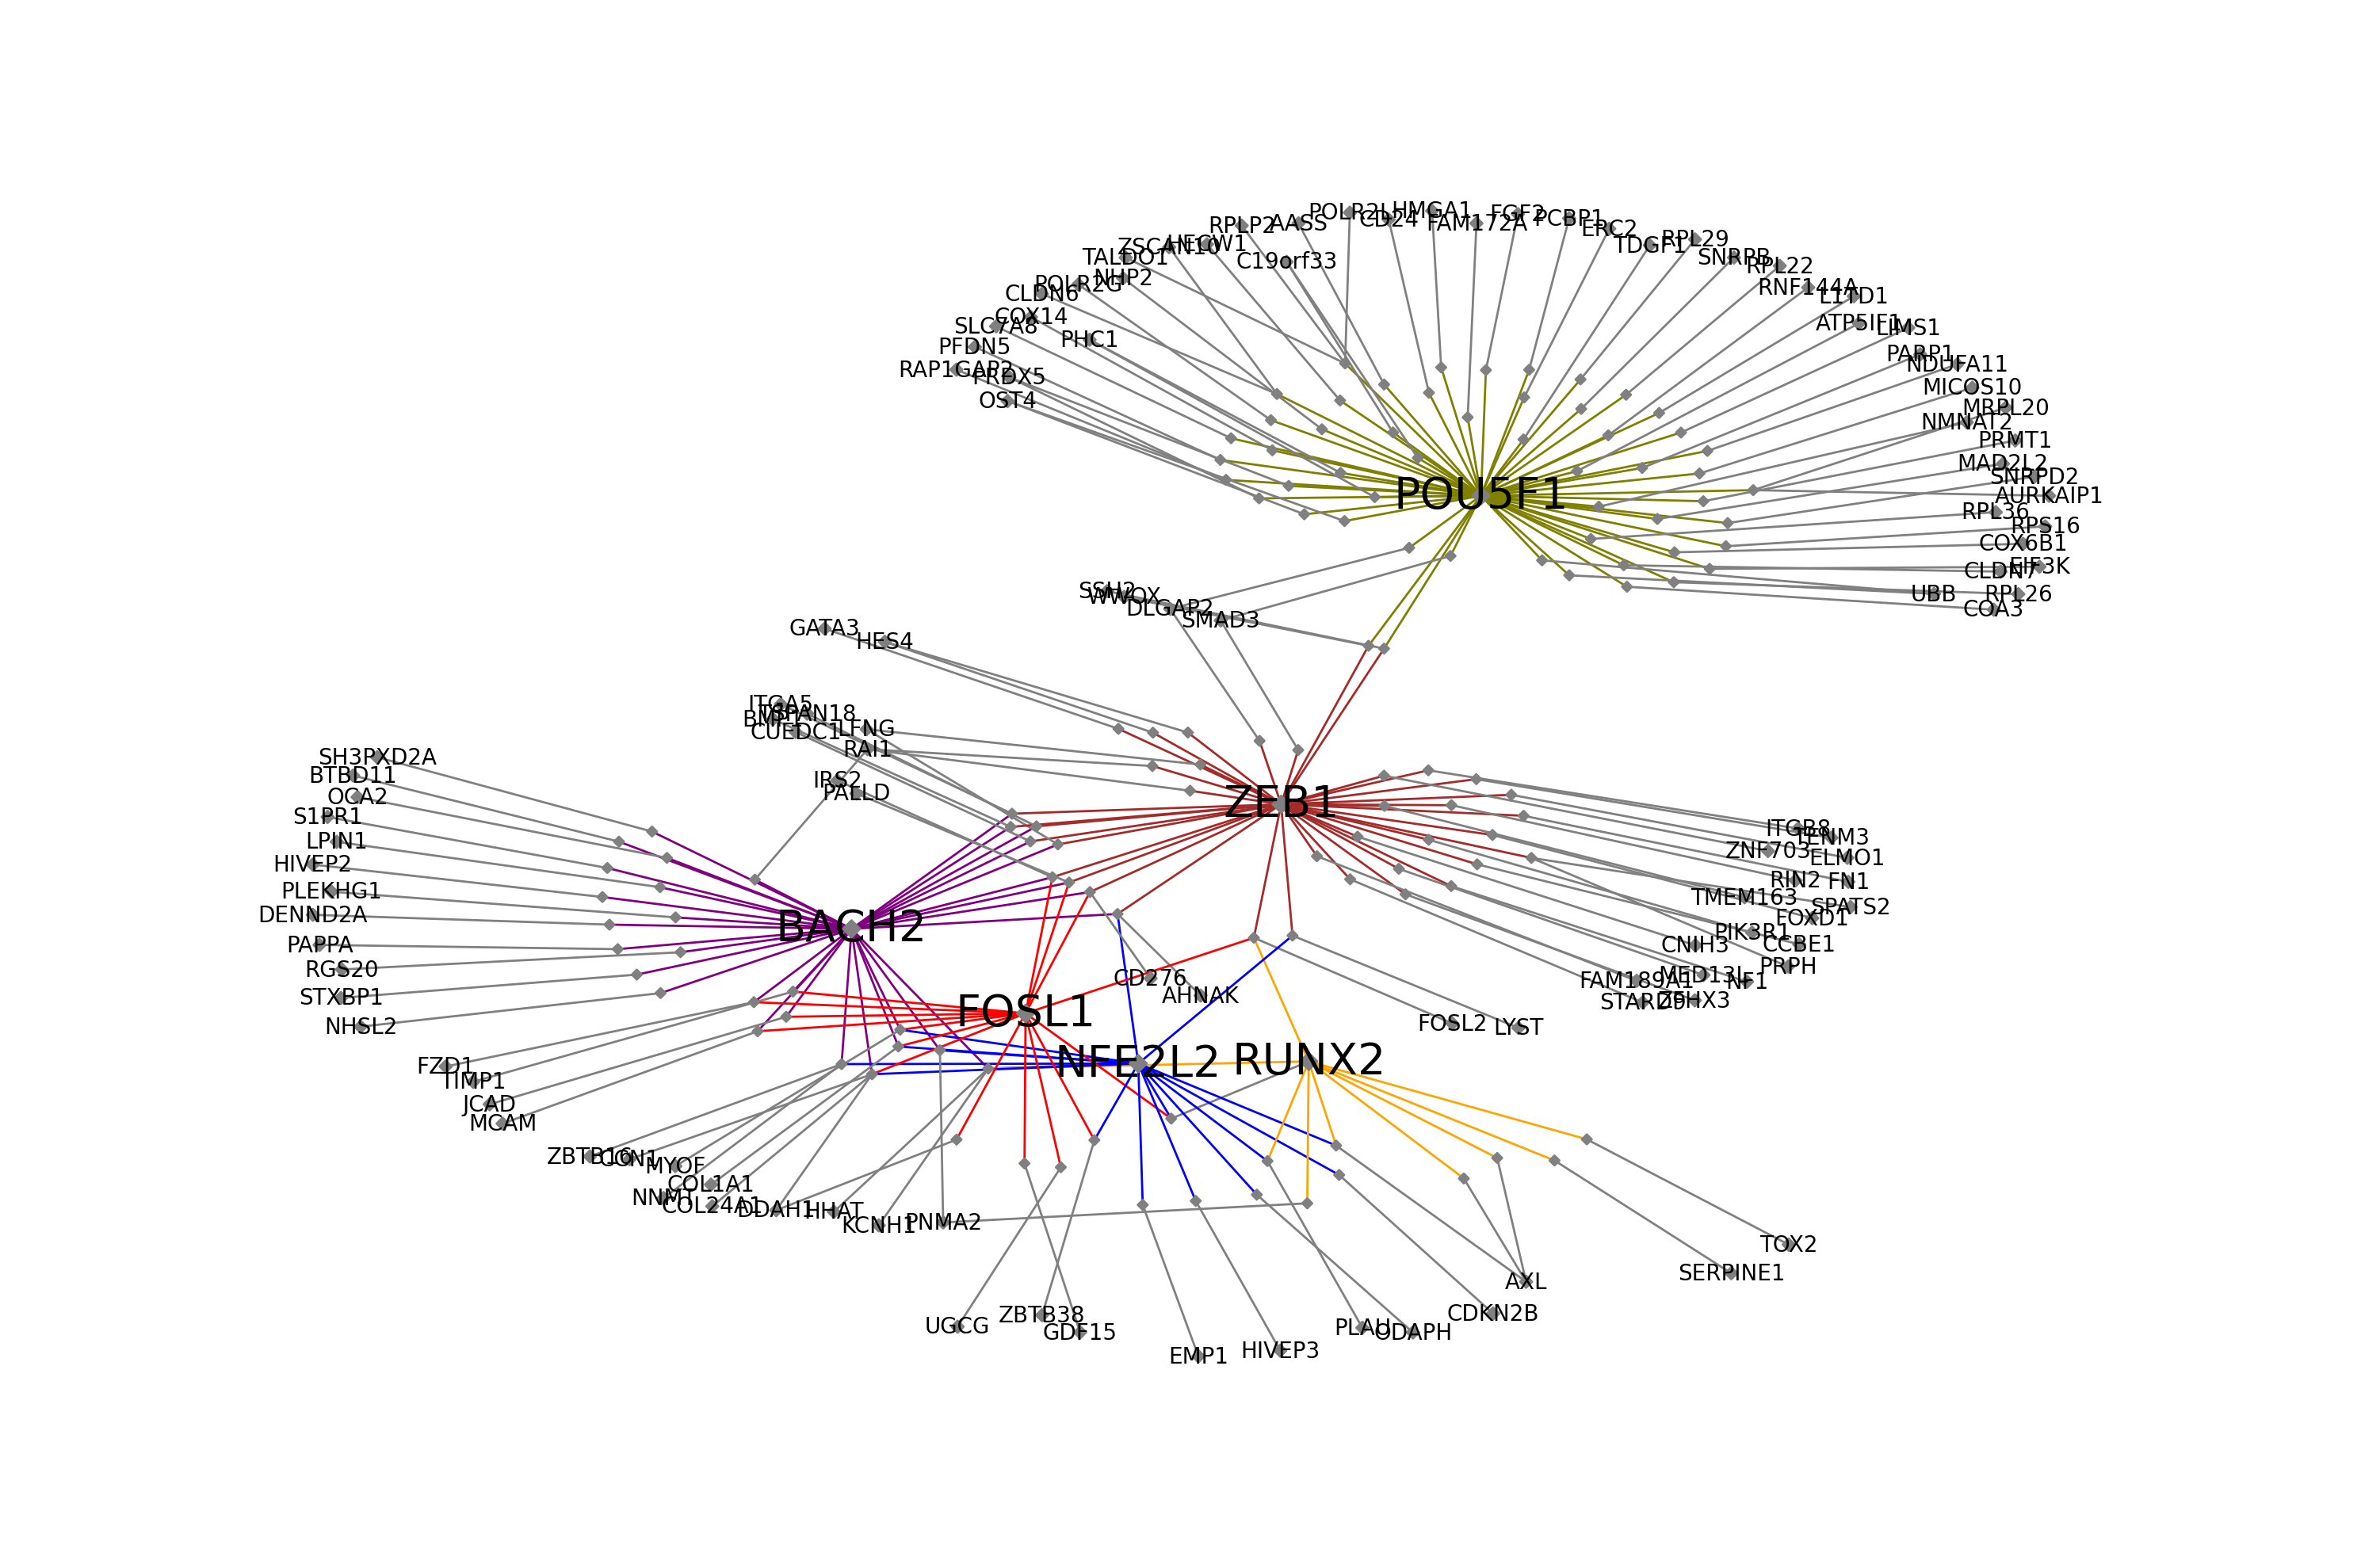

In [19]:
# Visualise the network
plt.figure(figsize=(15,10))
plot_networkx(G, pos)

## Network plot with differential expression/accessibility as colours

In [20]:
# We will use the top 1000 highly variable regions and genes
from pycisTopic.diff_features import find_highly_variable_features
hvr = find_highly_variable_features(scplus_obj.to_df('ACC').loc[list(set(scplus_obj.uns['eRegulon_metadata']['Region']))], n_top_features=500, plot = False)
hvg = find_highly_variable_features(scplus_obj.to_df('EXP')[list(set(scplus_obj.uns['eRegulon_metadata']['Gene']))].T, n_top_features=400, plot = False)

2026-07-23 21:54:48,325 cisTopic     INFO     Calculating mean
2026-07-23 21:54:48,329 cisTopic     INFO     Calculating variance
2026-07-23 21:54:48,416 cisTopic     INFO     Done!
2026-07-23 21:54:48,425 cisTopic     INFO     Calculating mean
2026-07-23 21:54:48,428 cisTopic     INFO     Calculating variance
2026-07-23 21:54:48,478 cisTopic     INFO     Done!


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [21]:
# Format the eRegulons into a table which can be used to create a network
from scenicplus.networks import create_nx_tables, create_nx_graph, plot_networkx, export_to_cytoscape
nx_tables = create_nx_tables(
    scplus_obj = scplus_obj,
    eRegulon_metadata_key ='eRegulon_metadata',
    subset_eRegulons = ['RUNX2', 'BACH2', 'ZEB1', 'NFE2L2', 'POU5F1'],
    subset_regions = hvr,
    subset_genes = hvg,
    add_differential_gene_expression = True,
    add_differential_region_accessibility = True,
    differential_variable = ['GEX_perturbation'])

In [22]:
dar_grn_deg = pd.read_csv('DAR_DEG_GRN.csv')
dar_grn_deg = dar_grn_deg[dar_grn_deg['Cell_type']=='RUNX2']

In [23]:
dar_grn_deg

,Unnamed: 0,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak,Triplet,...,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,deg_score,deg_logFC,deg_pval,deg_FDR
507518,507518,chr8,1059445,1059945,5.602407,0.000030,0.431540,RUNX2,chr8:1059445-1059945,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
507519,507519,chr1,24964880,24965380,3.503636,0.000075,0.381466,RUNX2,chr1:24964880-24965380,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
507520,507520,chr10,1253841,1254341,7.077293,0.000075,0.540503,RUNX2,chr10:1253841-1254341,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
507521,507521,chr15,78065417,78065917,5.388030,0.000075,0.505902,RUNX2,chr15:78065417-78065917,TEAD1#chr15:78065417-78065917#TBC1D2B,...,TEAD1#TBC1D2B,7.0,7.0,7.0,7.0,14.0,3.141811,0.816481,0.001679,0.022728
507522,507522,chr5,957270,957770,3.749521,0.000075,0.431795,RUNX2,chr5:957270-957770,MEIS2#chr5:957270-957770#NKD2,...,MEIS2#NKD2,6.0,10.0,6.0,6.0,13.0,1.777747,2.189634,0.075445,0.563202
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
591896,591896,chrX,154074124,154074624,-0.738756,1.000000,-0.005739,RUNX2,chrX:154074124-154074624,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591897,591897,chrX,154374194,154374694,0.328080,1.000000,0.014548,RUNX2,chrX:154374194-154374694,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591898,591898,chrX,154397920,154398420,0.163039,1.000000,0.012188,RUNX2,chrX:154397920-154398420,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591899,591899,chrX,154486716,154487216,0.316518,1.000000,0.030004,RUNX2,chrX:154486716-154487216,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np

# Use only 20%-80% of the colormap and no middle

colors = np.vstack([
    cm.RdGy_r(np.linspace(0.0, 0.4, 128)),  # blue → light blue
    cm.RdGy_r(np.linspace(0.5, 1.0, 128))   # light red → red
])

truncated_clr = mcolors.LinearSegmentedColormap.from_list(
    'truncated',
    colors
)

In [25]:
# Adds DEG log2FC to Gene nodes and DAR log2FC to Region nodes, then builds the graph.

gene_fc = (
    dar_grn_deg[['Gene', 'deg_logFC']]
    .dropna()
    .drop_duplicates('Gene')
    .rename(columns={'deg_logFC': 'log2fc_deg'})
)

region_fc = (
    dar_grn_deg[['Region', 'Log2FC']]
    .dropna()
    .drop_duplicates('Region')
    .rename(columns={'Log2FC': 'log2fc_dar'})
)

nx_tables['Node']['Gene'] = nx_tables['Node']['Gene'].merge(
    gene_fc,
    on='Gene',
    how='left'
)

nx_tables['Node']['Region'] = nx_tables['Node']['Region'].merge(
    region_fc,
    on='Region',
    how='left'
)

# Gene DEG statistics
gene_stats = (
    dar_grn_deg[['Gene', 'deg_logFC', 'deg_FDR']]
    .dropna(subset=['Gene'])
    .drop_duplicates('Gene')
)

gene_stats['neglog10_fdr'] = -np.log10(gene_stats['deg_FDR'].clip(lower=1e-300))

# Region DAR statistics
region_stats = (
    dar_grn_deg[['Region', 'Log2FC', 'FDR']]
    .dropna(subset=['Region'])
    .drop_duplicates('Region')
)

region_stats['neglog10_fdr'] = -np.log10(region_stats['FDR'].clip(lower=1e-300))

# rescale
gene_stats['node_size'] = (
    500 + 50 * gene_stats['neglog10_fdr']
)

region_stats['node_size'] = (
    500 + 30 * region_stats['neglog10_fdr']
)

# Gene nodes
nx_tables['Node']['Gene'] = nx_tables['Node']['Gene'].merge(
    gene_stats[['Gene', 'deg_logFC', 'node_size', 'neglog10_fdr']],
    on='Gene',
    how='left'
)

# TF nodes
nx_tables['Node']['TF'] = nx_tables['Node']['TF'].merge(
    gene_stats[['Gene', 'deg_logFC', 'node_size', 'neglog10_fdr']],
    left_on='TF',
    right_on='Gene',
    how='left'
).drop(columns='Gene')

# Region nodes
nx_tables['Node']['Region'] = nx_tables['Node']['Region'].merge(
    region_stats[['Region', 'Log2FC', 'node_size', 'neglog10_fdr']],
    on='Region',
    how='left'
)

In [26]:
G, pos, edge_tables, node_tables = create_nx_graph(
    nx_tables,
    use_edge_tables=['TF2R', 'R2G'],

    color_edge_by={
        'TF2R': {
            'variable': 'TF',
            'category_color': {
                'RUNX2': 'Orange',
                'BACH2': 'Purple',
                'FOSL1': 'Red',
                'ZEB1': 'Brown',
                'NFE2L2': 'Blue',
                'POU5F1': 'Olive'
            }
        }
    },

    color_node_by = {
        'TF': {
            'variable': 'deg_logFC',
            'continuous_color': truncated_clr,
            'v_min': -2,
            'v_max': 2
        },
        'Gene': {
            'variable': 'deg_logFC',
            'continuous_color': truncated_clr,
            'v_min': -2,
            'v_max': 2
        },
        'Region': {
            'variable': 'Log2FC',
            'continuous_color': truncated_clr,
            'v_min': -2,
            'v_max': 2
        }
    },

    size_node_by = {
        'TF': {
            'variable': 'node_size'
        },
        'Gene': {
            'variable': 'node_size'
        },
        'Region': {
            'variable': 'node_size'
        }
    },

    shape_node_by={
        'TF': {'variable': 'fixed_shape', 'fixed_shape': 'dot'},
        'Gene': {'variable': 'fixed_shape', 'fixed_shape': 'dot'},
        'Region': {'variable': 'fixed_shape', 'fixed_shape': 'dot'}
    },

    label_size_by={
        'TF': {'variable': 'fixed_label_size', 'fixed_label_size': 20.0},
        'Gene': {'variable': 'fixed_label_size', 'fixed_label_size': 10.0},
        'Region': {'variable': 'fixed_label_size', 'fixed_label_size': 0.0}
    },

    layout='kamada_kawai_layout',
    scale_position_by=250
)

In [27]:
# Scales node sizes separately for TF, Gene, and Region nodes.

for n, d in G.nodes(data=True):
    if d['group'] == 'TF':
        d['size'] = d['size'] * 20
    elif d['group'] == 'Gene':
        d['size'] = d['size'] * 10
    elif d['group'] == 'Region':
        d['size'] = d['size'] * 5

# Forces final node shapes directly on the graph object.

for n, d in G.nodes(data=True):
    if d['group'] == 'Region':
        d['shape'] = 'ellipse'
    elif d['group'] in ['TF', 'Gene']:
        d['shape'] = 'ellipse'      # pyvis/vis.js
        # d['shape'] = 'ellipse'  # try this instead if dot fails

In [28]:
# Removes one gene and all Region nodes directly connected to it.

gene = "UBB"

regions_to_remove = [
    n for n in G.neighbors(gene)
    if G.nodes[n].get("group") == "Region"
]

G.remove_nodes_from([gene] + regions_to_remove)

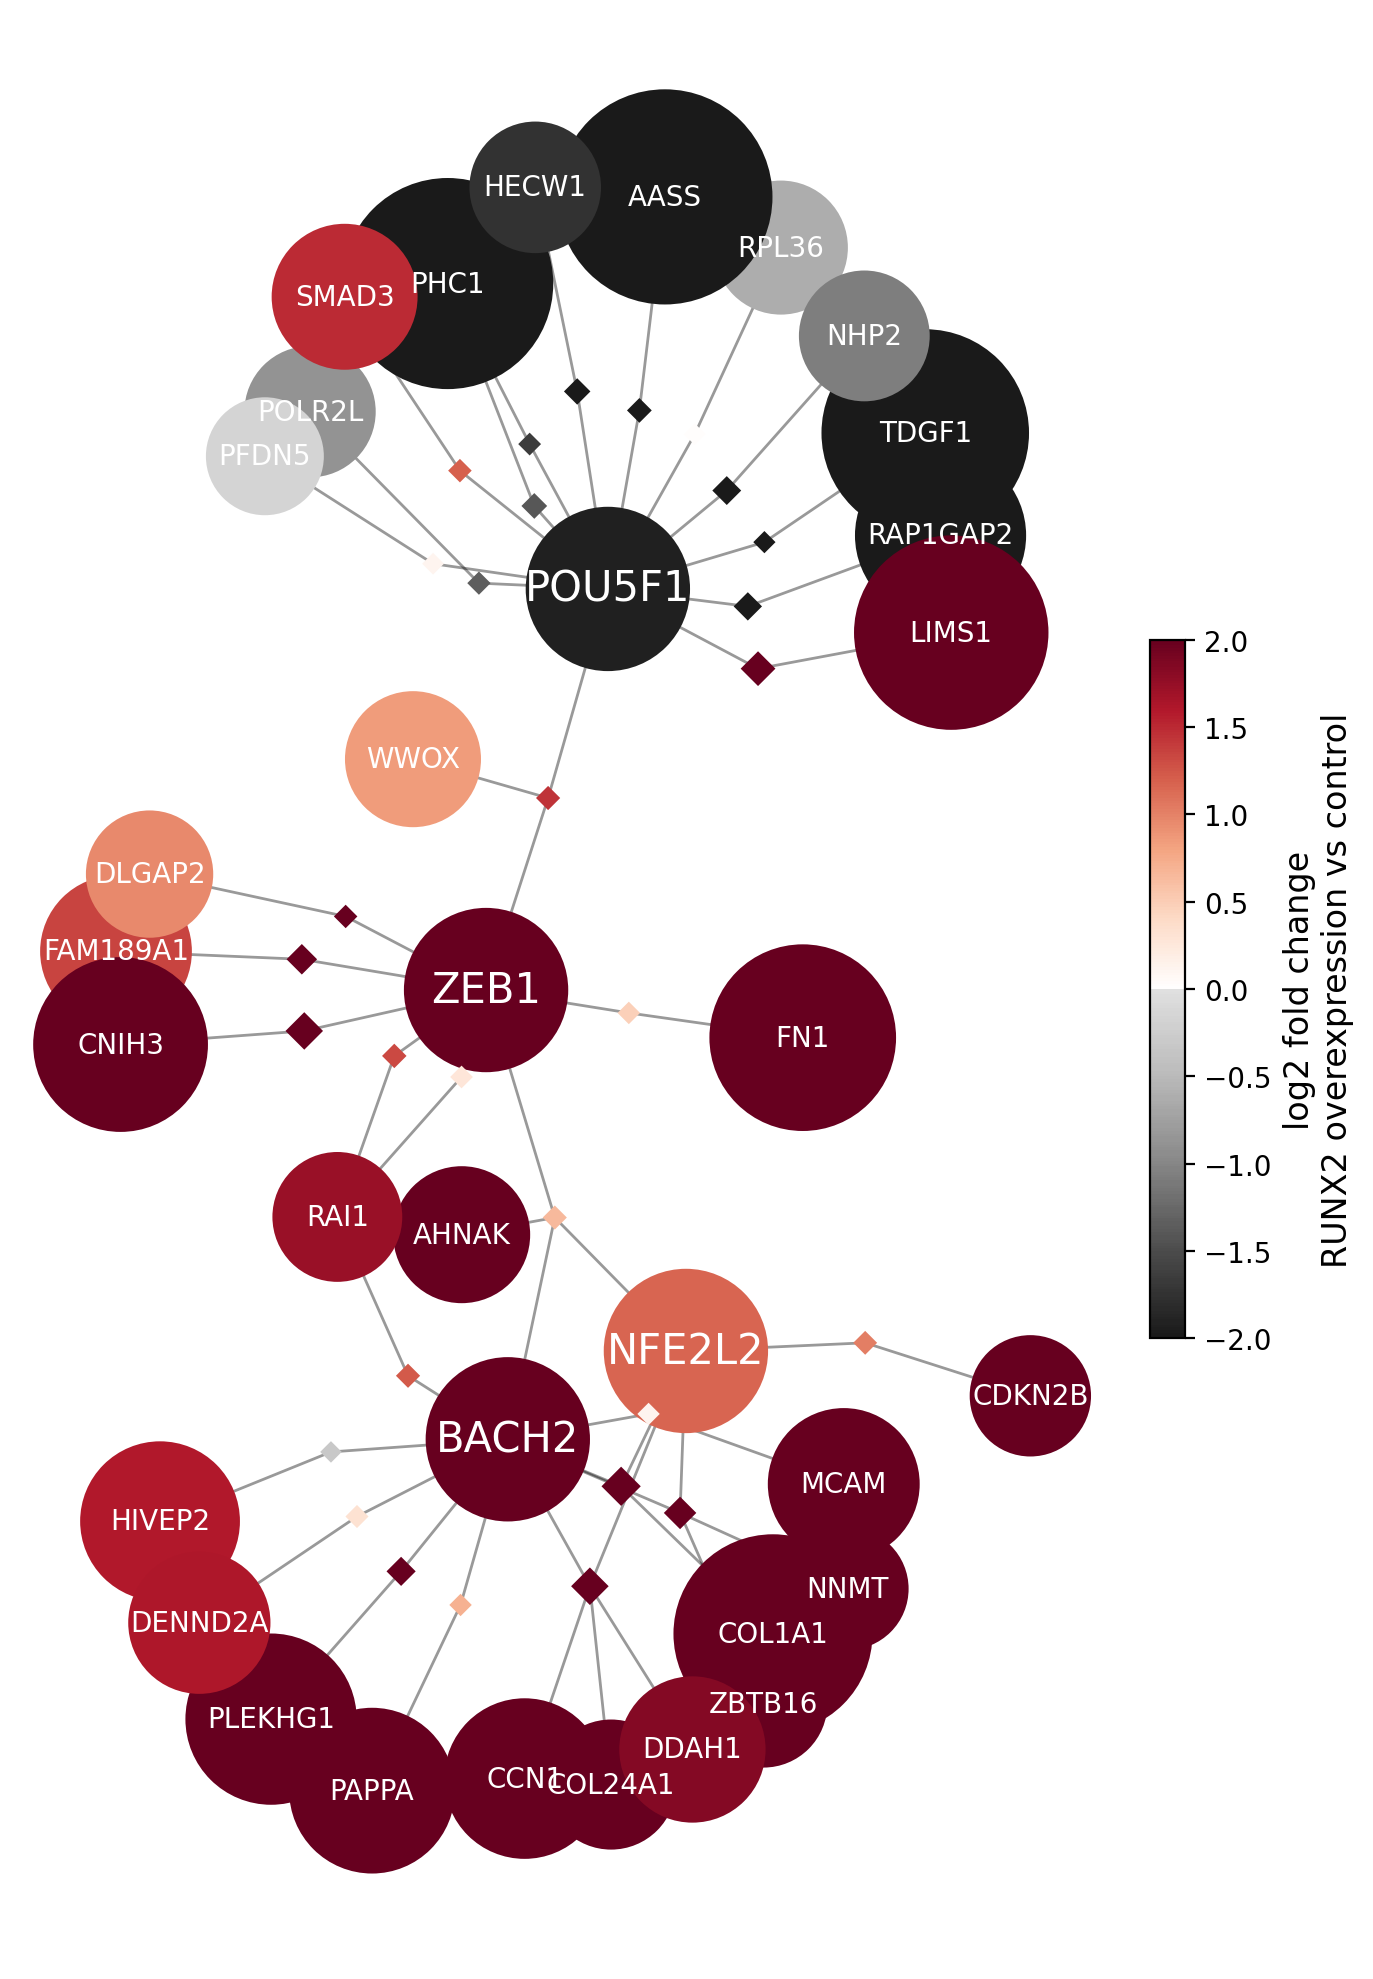

In [29]:
# Draws NetworkX graph with separate node shapes and larger node sizes.

import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(7, 10))

# Draw edges
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.4,
    width=1
)

# Split nodes by group
tf_nodes = [n for n, d in G.nodes(data=True) if d.get('group') == 'TF']
gene_nodes = [n for n, d in G.nodes(data=True) if d.get('group') == 'Gene']
region_nodes = [n for n, d in G.nodes(data=True) if d.get('group') == 'Region']


# Draw TF nodes as circles
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=tf_nodes,
    node_shape='o',
    node_size=3500,
    node_color=[G.nodes[n]['color'] for n in tf_nodes],
    edgecolors='none',
    linewidths=0
)

# Draw Gene nodes as circles
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=gene_nodes,
    node_shape='o',
    node_size=[G.nodes[n]['size'] * 60 for n in gene_nodes],
    node_color=[G.nodes[n]['color'] for n in gene_nodes],
    edgecolors='none',
    linewidths=0
)

# Draw Region nodes as diamonds
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=region_nodes,
    node_shape='D',
    node_size=[G.nodes[n]['size'] * 2 for n in region_nodes],
    node_color=[G.nodes[n]['color'] for n in region_nodes],
    edgecolors='none',
    linewidths=0
)

# Draw labels only where font_size > 0
tf_labels = {
    n: d['label']
    for n, d in G.nodes(data=True)
    if d['group'] == 'TF'
}

gene_labels = {
    n: d['label']
    for n, d in G.nodes(data=True)
    if d['group'] == 'Gene'
}

nx.draw_networkx_labels(
    G,
    pos,
    font_color='white',
    labels=tf_labels,
    font_size=15,   # same as your original TF font_size
)

nx.draw_networkx_labels(
    G,
    pos,
    font_color='white',
    labels=gene_labels,
    font_size=10    # same as your original Gene font_size
)

plt.axis('off')

import matplotlib as mpl
import matplotlib.colors as mcolors

# Match the range used when coloring the nodes
norm = mcolors.Normalize(vmin=-2, vmax=2)

sm = mpl.cm.ScalarMappable(
    cmap=truncated_clr,   # your custom colormap
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=plt.gca(),
    fraction=0.03,
    pad=0.02
)

cbar.set_label("log2 fold change\nRUNX2 overexpression vs control", fontsize=12)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("RUNX2_network.pdf")

plt.show()